libraries

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import gamma as G
from scipy.special import polygamma
from scipy.stats import gamma,norm
from scipy.signal import convolve
from tifffile import imread

pi = np.pi

segmented video opening 

In [ ]:
mat_full_image = imread('C:/Users/Maelig/Documents/Research/molecule_detection/research/tiff_files/long_cool_scan.tif',key = range(0,200))
scan_shape=mat_full_image.shape

background parameters

Fit result alpha=196.48241143575677, loc=0.0, theta=2.078209957910207


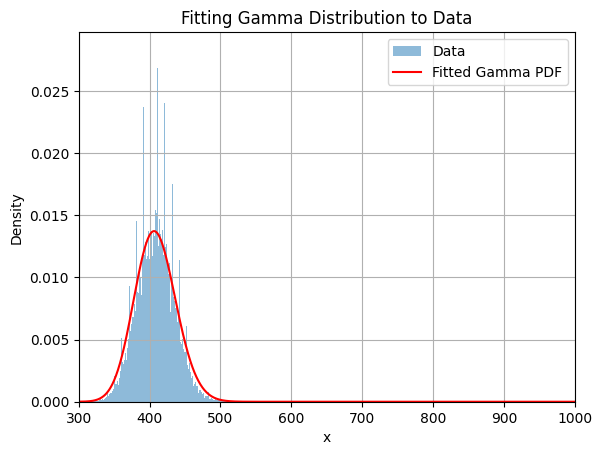

In [19]:
raveled_mat=np.ravel(mat_full_image[0])
raveled_mat_bg = raveled_mat[raveled_mat<700]

alpha, loc, theta = gamma.fit(raveled_mat_bg, floc=0.0)

print(f"Fit result alpha={alpha}, loc={loc}, theta={theta}")

x = np.linspace(start=300, stop=1000, num=1000)
pdf_fitted = gamma.pdf(x, a=alpha, loc=loc, scale=theta)

# Plot histogram and fitted curve
plt.hist(raveled_mat_bg, bins='auto', density=True, alpha=0.5, label='Data')
plt.plot(x, pdf_fitted, 'r-', label='Fitted Gamma PDF')
plt.xlim([300,1000])
plt.title('Fitting Gamma Distribution to Data')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

## Filtering

parameters

In [20]:
b=alpha*theta #background value: alpha*theta
a=np.max(mat_full_image[mat_full_image < np.quantile(mat_full_image, 0.99999)])-b
sigma=(1/2.3548)*2.7 # Calculated in the dedicated notebook
gamma = 2.7 # fwhm Calculated in the dedicated notebook

print(a,b,sigma)

266.66829599999994 408.33170400000006 1.1465941905894346


functions

In [21]:
def ln_transform(r_mn,theta):
    return np.log(r_mn)-np.log(theta) # modification of the dtype for memory/speed issues

def s_mn(l, m, n, sigma):
    return (1/pi)*(gamma/(l**2+gamma**2))*np.exp(-(m**2+n**2)/(2*sigma**2))/(2*pi*sigma**2)

def Kernel(a, L, T): 
    m = np.arange(-L,L+1).reshape(2*L+1,1)
    n = np.arange(-L,L+1).reshape(1,2*L+1)
    M = np.repeat(m, 2*L+1 ,1)
    N = np.repeat(n, 2*L+1 ,0)
    O = np.arange(-T, T+1)
    K = a * s_mn(O[:,np.newaxis,np.newaxis], M[np.newaxis,:], N[np.newaxis,:], sigma)
    return K

def digamma(z):
    return polygamma(0,z)

def trigamma(z):
    return polygamma(1,z)

def inv_gauss(x):
    return norm.isf(x, loc=0, scale=1)

def tau(a, alpha, P_FP, L, T):
    """ 
    Parameters:
    * a: signal value
    * alpha: alpha matrix
    * P_FP: probability of false positive
    * L: kernel size
    * T: kernel freq size
    """
    W1 = Kernel(a, L, T)
    W2 = W1**2
    w1 = W1.sum()
    w2 = W2.sum()
    return np.sqrt(w2*trigamma(alpha))*inv_gauss(P_FP)+w1*digamma(alpha)

filtering process

In [22]:
N = 4
kernel_size = 3 ## if it is change, you have to also change K (bg kernel) to match the sizes


ker = Kernel(a, kernel_size, N)
mat_full_image[np.where(mat_full_image == 0)] = 1 # prevent to have log of 0 

log_transformed_mat = ln_transform(mat_full_image,theta)
print("The size of the log transformed image is", log_transformed_mat.shape)

filtered_mat = convolve(log_transformed_mat, ker, mode='valid')
print("The size of the filtered image is", filtered_mat.shape)

The size of the log transformed image is (200, 500, 500)
The size of the filtered image is (192, 494, 494)


## threshold

adaptive background

In [23]:
K=(1/(40*(2*N+1)))*np.array([[[1,1,1,1,1,1,1],
                              [1,1,1,1,1,1,1],
                              [1,1,0,0,0,1,1],
                              [1,1,0,0,0,1,1],
                              [1,1,0,0,0,1,1],
                              [1,1,1,1,1,1,1],
                              [1,1,1,1,1,1,1]]]*(2*N+1)) ## warning : the size of K must matched the kernel_size to make the bg and the filtered image sizes matched

bg_adaptive = convolve(mat_full_image, K, mode='valid')
print("The size of the bg element image is", bg_adaptive.shape)

The size of the bg element image is (192, 494, 494)


threshold

In [24]:
P_FP = 1e-9
Alpha = bg_adaptive/theta

tau_mat = tau(a,Alpha, P_FP, kernel_size, N)
print("The size of the tau image is", tau_mat.shape)

T = filtered_mat >= tau_mat

The size of the tau image is (192, 494, 494)


## local max coordinates

In [25]:
##init

coordinates = np.nonzero(T[:,:,1:])
values = filtered_mat[coordinates[0],coordinates[1],coordinates[2]]
permutation = np.argsort(values)[::-1]
coordinates_sorted = coordinates[0][permutation],coordinates[1][permutation],coordinates[2][permutation]
values_sorted = values[permutation]
# print(np.max(values),values_sorted)
is_local_max=np.full(len(coordinates[0]),0)

[ 1 -1  1 ... -1 -1 -1]
[ True False  True ... False False False]
(array([ 24, 109, 108, 127,  29, 125,  96, 116, 157,   0, 179, 191, 135,
       113, 121,  69, 182, 149,  85,  86,  74, 119, 176,   2, 170, 180,
        45, 116,  68, 139,  13, 124, 150, 139, 163,  34,  21,  77, 190,
       156, 108,  62,  55, 131]), array([240, 240, 284, 384, 312, 328, 179, 181, 178, 261, 181, 235, 181,
       126, 276,  92, 186, 328, 435, 441, 206, 176, 244, 221, 375, 141,
       434, 129, 342, 390, 124, 324, 316, 364, 312, 203, 365, 283, 204,
       353, 374, 363, 419, 347]), array([ 60,  60, 140, 241, 158,  84, 211, 114, 213, 103, 116,  31, 116,
       157, 102, 290, 212,  84, 345, 349, 260, 213,  43,  80, 182, 153,
       158,  71,  78, 268, 257, 221, 111, 204, 157,  51, 199, 194,  50,
       133, 182, 195, 143,  10]))


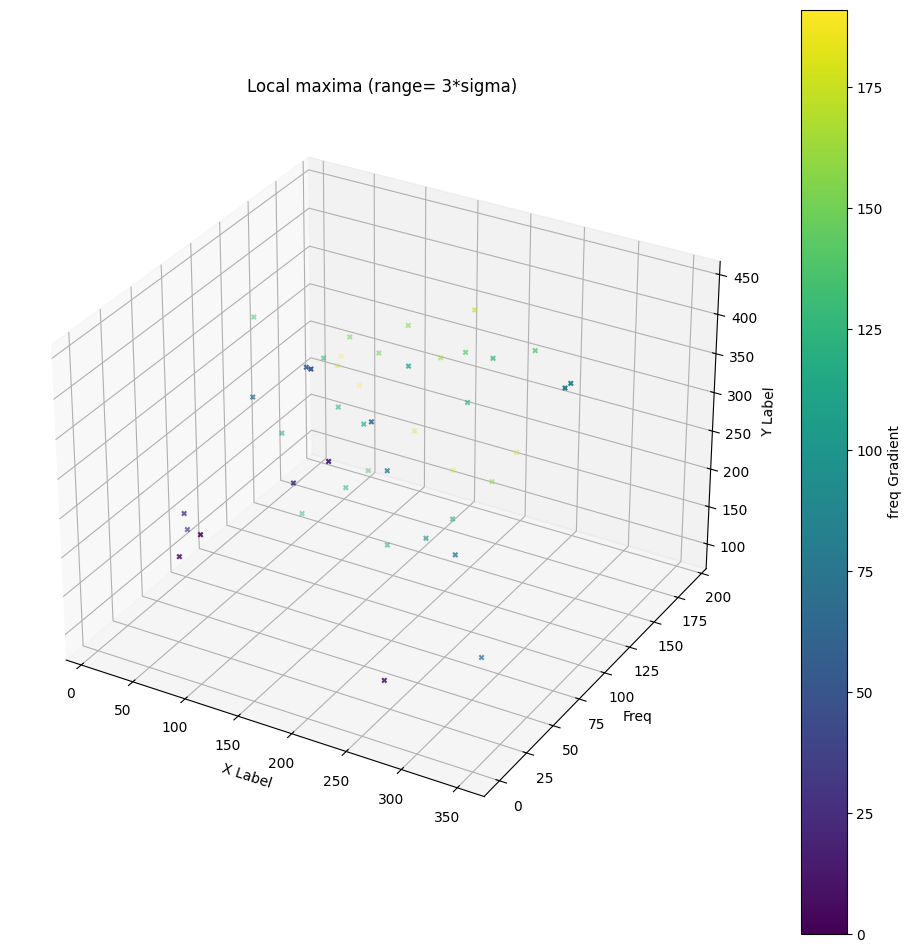

In [26]:
l = len(coordinates[0])
for i in range(l):
    if is_local_max[i] == 0 :
        # coordinates and distance
        l,m,n = coordinates_sorted[0][i],coordinates_sorted[1][i],coordinates_sorted[2][i]
        d = np.sqrt((coordinates_sorted[0]-l)**2 + (coordinates_sorted[1]-m)**2 + (coordinates_sorted[2]-n)**2)

        # neighborhood mask
        roi = (0 < d) & (d < 3*sigma)
        neighbor_coord = coordinates_sorted[0][roi],coordinates_sorted[1][roi],coordinates_sorted[2][roi]

        test = filtered_mat[l][m][n] > filtered_mat[neighbor_coord]
        local_max_test = np.all(test)

        is_local_max[roi] = np.where(test,-1,is_local_max[roi])
        if local_max_test == True :
            is_local_max[i] = 1
        else :
            is_local_max[i] = -1

    else :
        is_local_max[i] = -1

print(is_local_max)
local_max_mask = is_local_max == 1
print(local_max_mask)

local_max_coordinates = coordinates_sorted[0][local_max_mask],coordinates_sorted[1][local_max_mask],coordinates_sorted[2][local_max_mask]

print(local_max_coordinates)

fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')

# plt.matshow(mat_full_image[0], interpolation='none', cmap='viridis', vmax=np.quantile(mat_full_image, 0.999))
# plt.matshow(mat)
scatter=ax.scatter(local_max_coordinates[2],local_max_coordinates[0], local_max_coordinates[1],c=local_max_coordinates[0],marker='x', cmap='viridis',s=10)
plt.title("Local maxima (range= 3*sigma)")
colorbar = plt.colorbar(scatter)
colorbar.set_label('freq Gradient')
ax.set_xlabel('X Label')
ax.set_ylabel('Freq')
ax.set_zlabel('Y Label')
plt.show()

In [27]:
print(local_max_coordinates)

(array([ 24, 109, 108, 127,  29, 125,  96, 116, 157,   0, 179, 191, 135,
       113, 121,  69, 182, 149,  85,  86,  74, 119, 176,   2, 170, 180,
        45, 116,  68, 139,  13, 124, 150, 139, 163,  34,  21,  77, 190,
       156, 108,  62,  55, 131]), array([240, 240, 284, 384, 312, 328, 179, 181, 178, 261, 181, 235, 181,
       126, 276,  92, 186, 328, 435, 441, 206, 176, 244, 221, 375, 141,
       434, 129, 342, 390, 124, 324, 316, 364, 312, 203, 365, 283, 204,
       353, 374, 363, 419, 347]), array([ 60,  60, 140, 241, 158,  84, 211, 114, 213, 103, 116,  31, 116,
       157, 102, 290, 212,  84, 345, 349, 260, 213,  43,  80, 182, 153,
       158,  71,  78, 268, 257, 221, 111, 204, 157,  51, 199, 194,  50,
       133, 182, 195, 143,  10]))


In [28]:
permutation2 = np.argsort(local_max_coordinates[0])[::]
local_max_coordinates_sorted = local_max_coordinates[0][permutation2],local_max_coordinates[1][permutation2],local_max_coordinates[2][permutation2]
print(local_max_coordinates_sorted)

# start=0
# end=40
# c=0
# for i in range(start,end):
#     fig, ax = plt.subplots(figsize=(12, 12))
#     ax.matshow(filtered_mat[i])
#     while i == local_max_coordinates_sorted[0][c]:
#         plt.scatter(local_max_coordinates_sorted[2][c],local_max_coordinates_sorted[1][c], s=1000, facecolors='none', edgecolors='r', lw=1)
#         c=c+1
#     plt.show()

(array([  0,   2,  13,  21,  24,  29,  34,  45,  55,  62,  68,  69,  74,
        77,  85,  86,  96, 108, 108, 109, 113, 116, 116, 119, 121, 124,
       125, 127, 131, 135, 139, 139, 149, 150, 156, 157, 163, 170, 176,
       179, 180, 182, 190, 191]), array([261, 221, 124, 365, 240, 312, 203, 434, 419, 363, 342,  92, 206,
       283, 435, 441, 179, 284, 374, 240, 126, 181, 129, 176, 276, 324,
       328, 384, 347, 181, 364, 390, 328, 316, 353, 178, 312, 375, 244,
       181, 141, 186, 204, 235]), array([103,  80, 257, 199,  60, 158,  51, 158, 143, 195,  78, 290, 260,
       194, 345, 349, 211, 140, 182,  60, 157, 114,  71, 213, 102, 221,
        84, 241,  10, 116, 204, 268,  84, 111, 133, 213, 157, 182,  43,
       116, 153, 212,  50,  31]))
